In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/pujarisurakshashankar/car-market-trend-analysis/main/data/CarDekho_Dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (301, 9)
Column names: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("\nDataset cleaned successfully!")
print("Updated shape:", df.shape)

display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Rows: 2

Dataset cleaned successfully!
Updated shape: (299, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
# Check available columns
print("Columns:", df.columns.tolist())

Columns: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [5]:
# Display column names
print("Column names:", df.columns.tolist())

# Create car age using the Year column
if "Year" in df.columns:
    df["Car_Age"] = 2026 - df["Year"]
    print("\nCar age created successfully!")

elif "year" in df.columns:
    df["Car_Age"] = 2026 - df["year"]
    print("\nCar age created successfully!")

else:
    print("\nYear column not found. Check the column names above.")

display(df.head())

Column names: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Car age created successfully!


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [6]:
# Check the dataset columns
print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Car_Age']


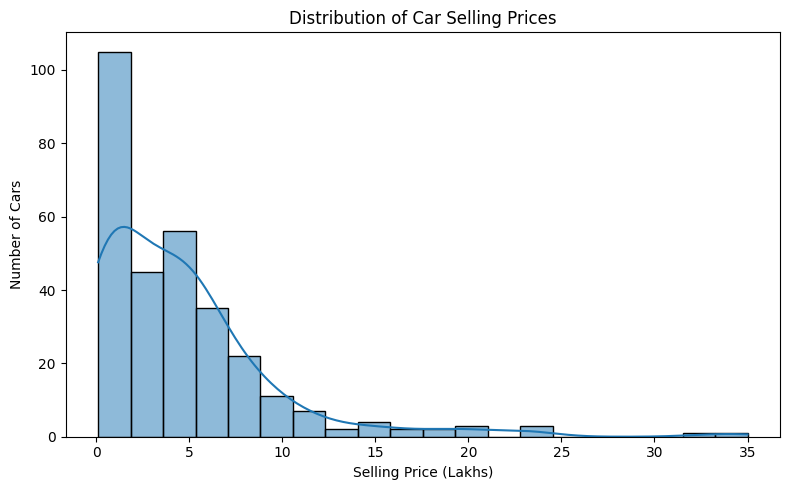

In [7]:
# Distribution of car selling prices
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Selling_Price", bins=20, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

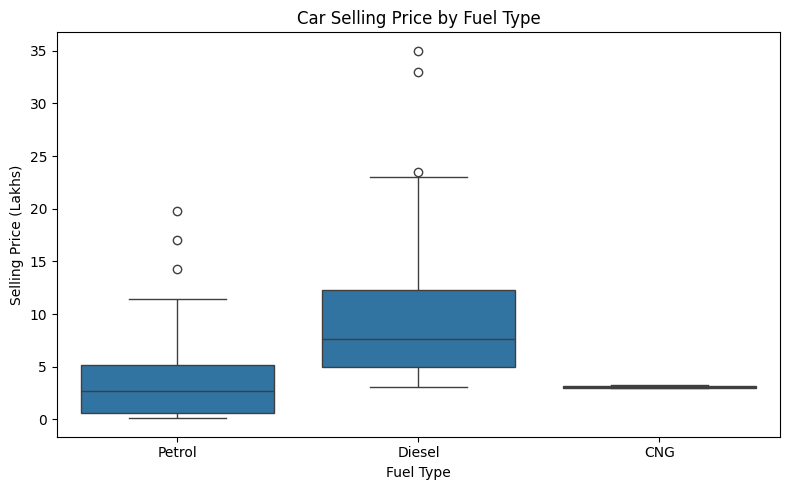

In [8]:
# Compare selling prices by fuel type
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Car Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.show()

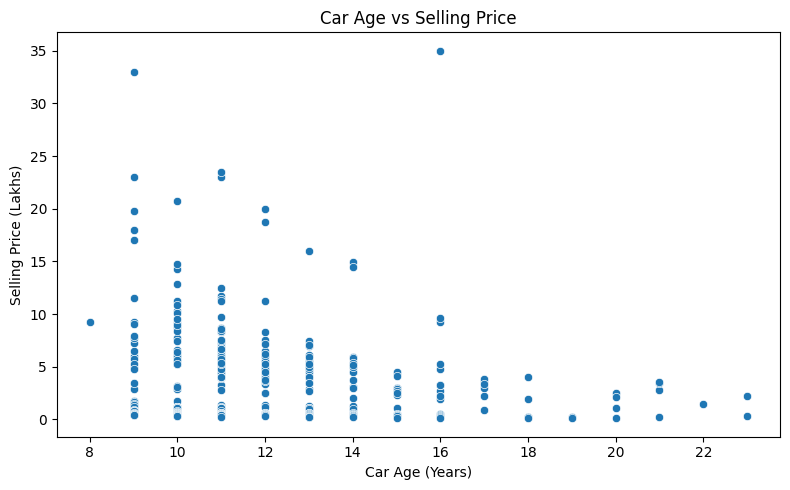

In [9]:
# Car age vs selling price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price"
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.show()

In [10]:
# Extract car brand from car name
df["Brand"] = df["Car_Name"].str.split().str[0]

print("Car brand extracted successfully!")

print("\nBrand counts:")
print(df["Brand"].value_counts().head(10))

display(df[["Car_Name", "Brand", "Car_Age", "Selling_Price"]].head())

Car brand extracted successfully!

Brand counts:
Brand
city        26
Bajaj       25
corolla     17
Royal       17
Honda       17
Hero        15
verna       14
etios       11
fortuner    10
brio        10
Name: count, dtype: int64


,Car_Name,Brand,Car_Age,Selling_Price
0,ritz,ritz,12,3.35
1,sx4,sx4,13,4.75
2,ciaz,ciaz,9,7.25
3,wagon r,wagon,15,2.85
4,swift,swift,12,4.60


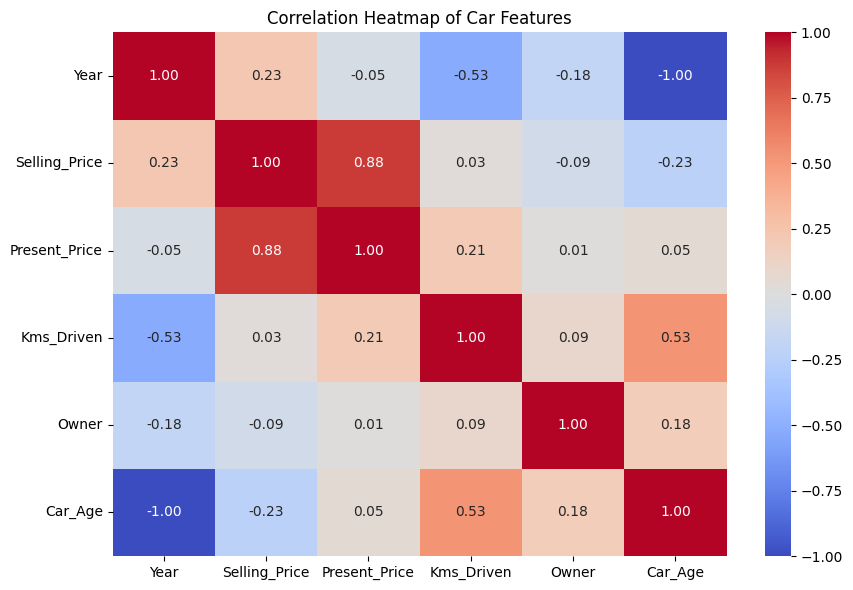

In [11]:
# Select numerical columns
numeric_data = df[
    ["Year", "Selling_Price", "Present_Price",
     "Kms_Driven", "Owner", "Car_Age"]
]

# Calculate correlation
correlation = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Car Features")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# Convert categorical data into numeric data
df_encoded = pd.get_dummies(
    df,
    columns=["Fuel_Type", "Seller_Type", "Transmission", "Brand"],
    drop_first=True,
    dtype=int
)

# Select input features
X = df_encoded.drop(
    columns=["Selling_Price", "Car_Name"]
)

# Select target variable
y = df_encoded["Selling_Price"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preparation completed!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data preparation completed!
Training data: (239, 52)
Testing data: (60, 52)


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

print("Linear Regression prediction:")
print(lr_model.predict(X_test[:5]))

print("\nRandom Forest prediction:")
print(rf_model.predict(X_test[:5]))

Both models trained successfully!
Linear Regression prediction:
[ 8.37270809  7.21310259  1.76151737  6.73624872 11.52964234]

Random Forest prediction:
[ 9.4704   7.95265  0.44335  7.2865  16.96575]


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predictions
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Evaluation function
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

# Compare both models
results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, lr_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.809,3.399,0.552
1,Random Forest,1.409,3.429,0.544


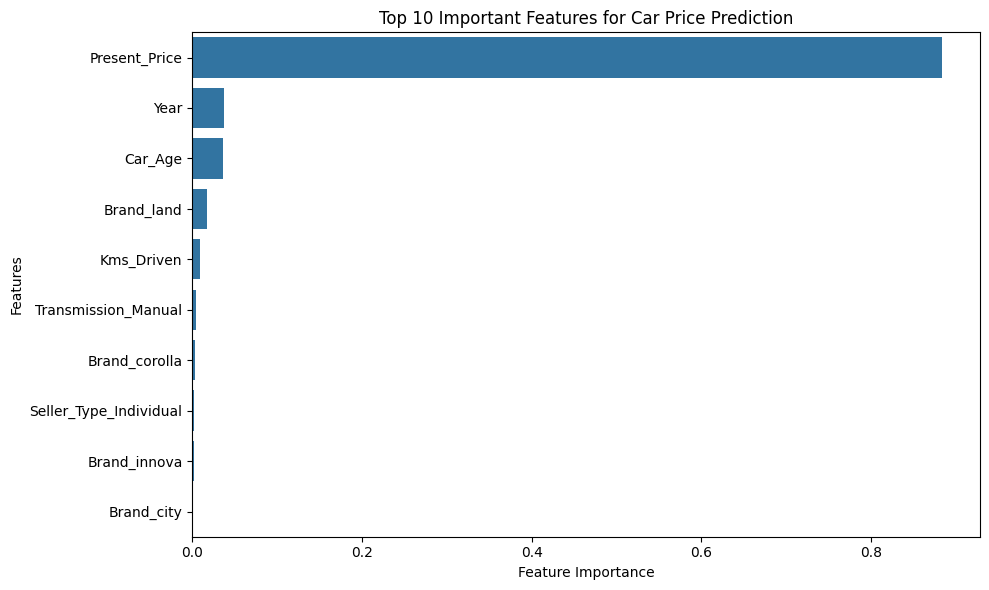

,Feature,Importance
1,Present_Price,0.884363
0,Year,0.037460
4,Car_Age,0.035981
42,Brand_land,0.016994
2,Kms_Driven,0.008729
8,Transmission_Manual,0.004876
28,Brand_corolla,0.003055
7,Seller_Type_Individual,0.001832
40,Brand_innova,0.001702
27,Brand_city,0.000930


In [15]:
# Get feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance", ascending=False
)

# Plot graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Car Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

display(importance.head(10))

## Conclusion – Car Price Prediction

In this project, a machine learning model was developed to predict used car selling prices using car-related features.

### Work Completed
- Loaded and explored the car dataset.
- Checked missing values and duplicate records.
- Created visualizations to understand selling prices, fuel types, and car age.
- Created a correlation heatmap to study relationships between numerical features.
- Prepared the data using categorical encoding.
- Split the dataset into 80% training data and 20% testing data.
- Trained Linear Regression and Random Forest Regression models.
- Evaluated model performance using MAE, RMSE, and R² score.
- Visualized feature importance using a bar chart.

### Final Observation
The two regression models were compared using their evaluation metrics. The model with lower prediction errors and a better R² score can be selected as the preferred model. Feature importance helps identify which car characteristics contribute most to the predictions.

### Learning Outcome
This project provided practical experience in data preprocessing, exploratory data analysis, data visualization, machine learning model training, and model evaluation using Python.